# Hipotezy H1 i H2

Wyniki testów zapisanych w preregistracji [`docs/hipotezy.md`](../docs/hipotezy.md). Liczy je `make hypotheses CONFIRMATORY=1` (`scripts/09_test_hypotheses.py`); ten notatnik tylko je pokazuje. Przebieg potwierdzający ma pierwszeństwo, a eksploracyjny jest wyraźnie oznaczony.

- **H1** (Reddit 2005–2018): maleje zaufanie do konsensusu naukowego. H1-A: udział postów `challenges` wśród postów o nauce (`stance_v1`). H1-B: udział źródeł konsensusu i źródeł alternatywnych wśród postów z powołaniem (`gliner_v1`).
- **H2** (Wikipedia 2020–2026): użytkownicy częściej odwołują się do źródeł alternatywnych; udział linków do blogów, mediów społecznościowych i serwisów wideo wśród linków dodanych do przypisów.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from digital_media_analysis.paths import AGREEMENT_DIR, HYPOTHESES_DIR, VALIDATION_DIR

mode = next((name for name in ["confirmatory", "exploratory"] if (HYPOTHESES_DIR / f"{name}_run.json").exists()), None)
if mode is None:
    print("Brak wyników: hipotezy nie zostały jeszcze przetestowane (make hypotheses CONFIRMATORY=1 po commicie preregistracji).")
else:
    run = json.loads((HYPOTHESES_DIR / f"{mode}_run.json").read_text(encoding="utf-8"))
    print(f"Przebieg: {mode}, commit {run['commit'][:7]}, {run['created_utc']}")
    for key, value in run["notes"].items():
        print(f"{key}: {value}")

Przebieg: confirmatory, commit 440b5fb, 2026-10-24T11:44:51+00:00
H1-A: czeka na etykiety stanowiska: strojenie stance_v1 na dev, test (07b) i etykiety próby (08)
H2 unclassified links: 10


## Trendy

Iloraz szans na rok z 95% przedziałem i jednostronną wartością p w kierunku zapisanym w preregistracji. Analiza `primary` to test główny; pozostałe wiersze to analizy wrażliwości.

In [2]:
if mode is not None and (HYPOTHESES_DIR / f"{mode}_trends.csv").exists():
    trends = pd.read_csv(HYPOTHESES_DIR / f"{mode}_trends.csv")
    columns = ["hypothesis", "analysis", "outcome", "direction", "odds_ratio_per_year", "ci_low", "ci_high", "p_one_sided", "supported", "units", "positives", "note"]
    display(trends[columns].round(4))

,hypothesis,analysis,outcome,direction,odds_ratio_per_year,ci_low,ci_high,p_one_sided,supported,units,positives,note
0,H1-B,primary,consensus,decrease,1.0257,0.9914,1.0613,0.9283,False,5154,825,NaN
1,H1-B,primary,alternative,increase,0.9879,0.9656,1.0106,0.8530,False,5154,2271,NaN
2,H1-B,sensitivity_period,consensus,decrease,1.0418,1.0093,1.0753,0.9944,False,5945,978,NaN
3,H1-B,sensitivity_period,alternative,increase,0.9936,0.9762,1.0114,0.7593,False,5945,2579,NaN
4,H1-B,only_science,consensus,decrease,1.0317,0.9938,1.0710,0.9488,False,1919,413,NaN
5,H1-B,only_science,alternative,increase,0.9856,0.9565,1.0155,0.8293,False,1919,657,NaN
6,H1-B,only_conspiracy,consensus,decrease,1.0116,0.8998,1.1373,0.5766,False,1554,101,NaN
7,H1-B,only_conspiracy,alternative,increase,0.9950,0.9537,1.0381,0.5916,False,1554,741,NaN
8,H2,primary,alternative,increase,1.4704,1.0879,1.9874,0.0061,True,1207,10,NaN
9,H2,without_covid19,alternative,increase,1.3911,0.8308,2.3293,0.1047,False,105,2,NaN


## Udziały w kolejnych latach

Ważone udziały z 95% przedziałami bootstrap. Dla H1-B kolumna `corrected` to udział skorygowany o błąd instrumentu (Rogan–Gladen); przy małej liczbie przypadków w gold jest niepewny.

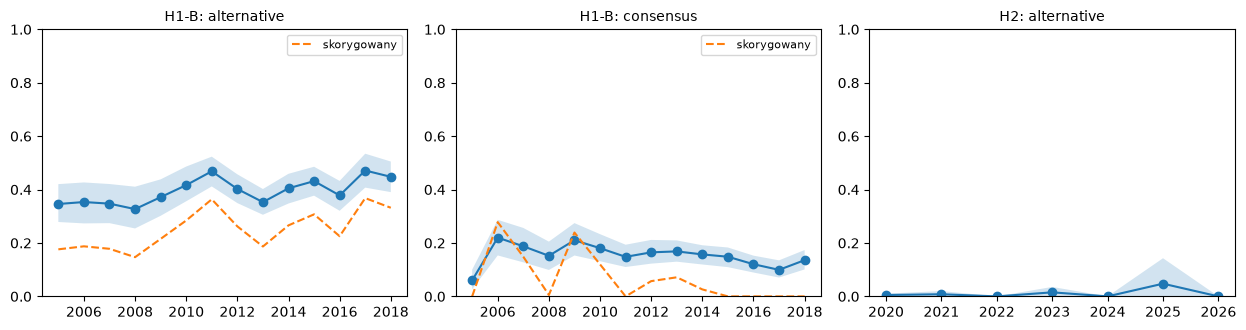

year                               2005  2006  2007  2008  2009  2010  2011  \
hypothesis outcome     group                                                  
H1-B       alternative conspiracy   NaN   NaN   NaN  0.41  0.44  0.45  0.60   
                       reddit.com  0.35   NaN   NaN   NaN   NaN   NaN   NaN   
                       science      NaN  0.35  0.35  0.32  0.36  0.40  0.41   
                       skeptic      NaN   NaN   NaN  0.63  0.66  0.54  0.55   
           consensus   conspiracy   NaN   NaN   NaN  0.05  0.07  0.07  0.04   
                       reddit.com  0.06   NaN   NaN   NaN   NaN   NaN   NaN   
                       science      NaN  0.22  0.19  0.15  0.22  0.20  0.18   
                       skeptic      NaN   NaN   NaN  0.19  0.20  0.19  0.29   

year                               2012  2013  2014  2015  2016  2017  2018  
hypothesis outcome     group                                                 
H1-B       alternative conspiracy  0.49  0.46  0.50  0.47  0.39  0.50  0.53  
                       reddit.com   NaN   NaN   NaN   NaN   NaN   NaN   NaN  
                       science     0.35  0.23  0.27  0.37  0.35  0.37  0.31  
                       skeptic     0.51  0.51  0.53  0.48  0.45  0.57  0.48  
           consensus   conspiracy  0.07  0.08  0.05  0.09  0.05  0.05  0.10  
                       reddit.com   NaN   NaN   NaN   NaN   NaN   NaN   NaN  
                       science     0.21  0.25  0.29  0.22  0.25  0.23  0.19  
                       skeptic     0.19  0.16  0.22  0.23  0.15  0.18  0.17

In [3]:
if mode is not None and (HYPOTHESES_DIR / f"{mode}_yearly.csv").exists():
    yearly = pd.read_csv(HYPOTHESES_DIR / f"{mode}_yearly.csv")
    overall = yearly[yearly["group"].eq("all")]
    panels = list(overall.groupby(["hypothesis", "outcome"]))
    figure, axes = plt.subplots(1, len(panels), figsize=(4.2 * len(panels), 3.4), squeeze=False)
    for axis, ((hypothesis, outcome), rows) in zip(axes[0], panels):
        axis.fill_between(rows["year"], rows["low"], rows["high"], alpha=0.2)
        axis.plot(rows["year"], rows["share"], marker="o")
        if "corrected" in rows and rows["corrected"].notna().any():
            axis.plot(rows["year"], rows["corrected"], linestyle="--", label="skorygowany")
            axis.legend(fontsize=8)
        axis.set_title(f"{hypothesis}: {outcome}", fontsize=10)
        axis.set_ylim(0, 1)
    figure.tight_layout()
    plt.show()
    by_group = yearly[yearly["group"].ne("all")]
    if len(by_group):
        display(by_group.pivot_table(index=["hypothesis", "outcome", "group"], columns="year", values="share").round(2))

## Stanowisko: zgodność annotatorów i walidacja instrumentu

Warunek trafności H1-A: `stance_v1` na zbiorze testowym musi osiągnąć F1 ≥ 0,5 dla `challenges` i κ ≥ 0,4.

In [4]:
for path in [AGREEMENT_DIR / "pilot_stance_agreement.csv", VALIDATION_DIR / "stance_test_metrics.csv", VALIDATION_DIR / "stance_dev_metrics.csv"]:
    if path.exists():
        print(path.name)
        display(pd.read_csv(path).round(3))
    else:
        print(f"{path.name}: jeszcze nie ma (etykiety stanowiska nie zostały zaimportowane albo instrument nie był walidowany).")

pilot_stance_agreement.csv: jeszcze nie ma (etykiety stanowiska nie zostały zaimportowane albo instrument nie był walidowany).
stance_test_metrics.csv: jeszcze nie ma (etykiety stanowiska nie zostały zaimportowane albo instrument nie był walidowany).
stance_dev_metrics.csv: jeszcze nie ma (etykiety stanowiska nie zostały zaimportowane albo instrument nie był walidowany).
